# Lab 4: Customer Segmentation Using Clustering and PCA

**Zhan Tabuldinov, BDA-2401**

In this lab I group the customers of a food retail company into segments with **K-Means clustering** and show the segments in two dimensions with **PCA**. The goal is to find groups of customers who behave in a similar way, so that marketing can work with each group differently.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
sns.set_theme(style="whitegrid")

## 1. Dataset Selection

**Dataset:** Customer Personality Analysis (Patel, 2021), published on Kaggle, license CC0.
**Link:** https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis

The data describes **2 240 customers** of a food retail company (wines, meat, fish, fruits, sweets, gold products) and has **29 columns**:

* **Who the customer is:** year of birth, education, marital status, income, number of kids and teens at home, date of registration.
* **What the customer buys:** money spent on 6 product groups in the last 2 years, number of purchases through the web, catalog and store, number of purchases with a discount, web visits per month, days since the last purchase.
* **How the customer reacts to marketing:** answers to 5 past campaigns and to the last one, complaints.

**Why it is suitable for segmentation.** Segmentation is an unsupervised learning task (Géron, 2019, ch. 9). There is no target column – we do not know the "right" groups. But we have many numeric features about spending and behaviour, so customers can be grouped by similarity. This is a classic unsupervised learning task, and the result (segments) is directly useful for marketing.

In [2]:
import kagglehub
path = kagglehub.dataset_download("imakash3011/customer-personality-analysis")
df = pd.read_csv(path + "/marketing_campaign.csv", sep="\t")
print(df.shape)
df.head()

(2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


## 2. Business Understanding

* **Problem.** The company sends the same campaigns and discounts to all customers. Some customers spend 2 000 € per year, others 50 €; some buy only with a discount, others never look at discounts. One message for everybody is expensive and works badly.
* **What segmentation gives.** Groups of customers with similar income, spending and buying habits. For every group the company can choose its own offer, channel and budget.
* **Decisions the segments support:**
  * *Marketing and targeting* – send premium wine offers to high spenders, send discount coupons only to the group that reacts to discounts.
  * *Pricing and promotions* – do not give discounts to customers who buy at full price anyway.
  * *Channel strategy* – customers who visit the website often but buy little need a better online shop; catalog buyers need the catalog.
  * *Resource allocation* – put the retention budget on the segment that brings most of the revenue.
* **Success criteria.** Segments should be (1) statistically reasonable – silhouette score clearly above 0 and a visible separation on the PCA plot, and (2) easy to describe in business words, with different income, spending and behaviour in each segment.

## 3. Exploratory Data Analysis

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [4]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.2,3246.7,0.0,2828.2,5458.5,8427.8,11191.0
Year_Birth,2240.0,1968.8,12.0,1893.0,1959.0,1970.0,1977.0,1996.0
Income,2216.0,52247.3,25173.1,1730.0,35303.0,51381.5,68522.0,666666.0
Kidhome,2240.0,0.4,0.5,0.0,0.0,0.0,1.0,2.0
Teenhome,2240.0,0.5,0.5,0.0,0.0,0.0,1.0,2.0
Recency,2240.0,49.1,29.0,0.0,24.0,49.0,74.0,99.0
MntWines,2240.0,303.9,336.6,0.0,23.8,173.5,504.2,1493.0
MntFruits,2240.0,26.3,39.8,0.0,1.0,8.0,33.0,199.0
MntMeatProducts,2240.0,167.0,225.7,0.0,16.0,67.0,232.0,1725.0
MntFishProducts,2240.0,37.5,54.6,0.0,3.0,12.0,50.0,259.0


2 240 rows, 29 columns. Most columns are integers (money spent, number of purchases, 0/1 flags). `Education` and `Marital_Status` are text, `Dt_Customer` is a date saved as text, `Income` has 24 missing values.

Some facts from the summary: the median income is about 51 000, but the maximum is 666 666 – a strange value. Year of birth goes from 1893 to 1996 – a customer born in 1893 would be 120+ years old, so these are errors. `Z_CostContact` and `Z_Revenue` are constants (3 and 11) and carry no information. Spending on wines (mean 304) and meat (167) is much bigger than on fruits, fish and sweets.

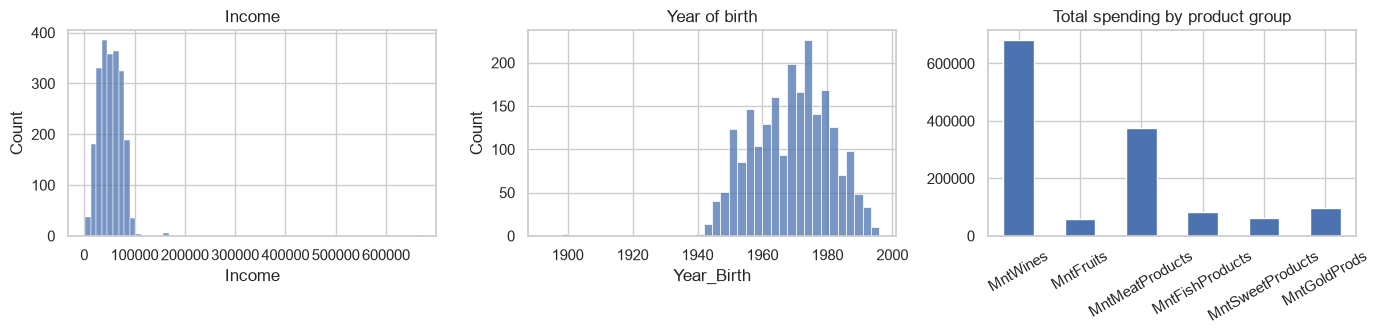

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
sns.histplot(df["Income"].dropna(), bins=60, ax=ax[0]).set(title="Income")
sns.histplot(df["Year_Birth"], bins=40, ax=ax[1]).set(title="Year of birth")
mnt = [c for c in df.columns if c.startswith("Mnt")]
df[mnt].sum().plot.bar(ax=ax[2], color="#4C72B0", rot=30, title="Total spending by product group")
plt.tight_layout(); plt.show()

**Figure 1.** Income is close to a normal distribution around 50 000, with one extreme value far to the right. Year of birth has a few points before 1940 that are far from the rest. Wine is more than half of all spending, then meat; sweets and fruits are small. This is a wine-and-meat retailer, so the "premium" customers are the wine and meat buyers.

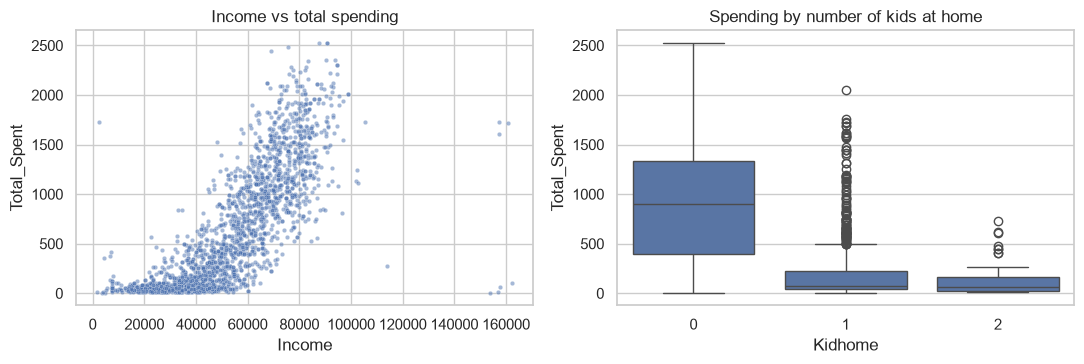

In [6]:
tmp = df.assign(Total_Spent=df[mnt].sum(axis=1))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.scatterplot(data=tmp[tmp["Income"] < 200000], x="Income", y="Total_Spent", s=10, alpha=0.5, ax=ax[0]).set(title="Income vs total spending")
sns.boxplot(data=tmp, x="Kidhome", y="Total_Spent", color="#4C72B0", ax=ax[1]).set(title="Spending by number of kids at home")
plt.tight_layout(); plt.show()

**Figure 2.** Spending grows with income, and the relation is not a straight line: below 40 000 almost everybody spends little, above 70 000 spending grows fast. Customers with kids at home spend much less than customers without kids. Income and family size will be the main axes of the segments.

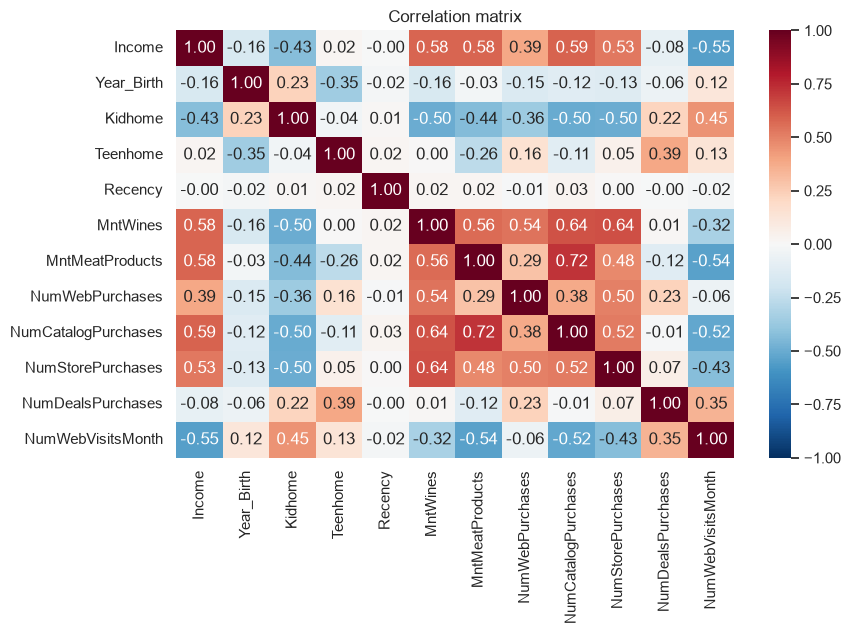

In [7]:
num = ["Income", "Year_Birth", "Kidhome", "Teenhome", "Recency", "MntWines", "MntMeatProducts", "NumWebPurchases",
       "NumCatalogPurchases", "NumStorePurchases", "NumDealsPurchases", "NumWebVisitsMonth"]
plt.figure(figsize=(9, 6.5))
sns.heatmap(df[num].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix"); plt.tight_layout(); plt.show()

**Figure 3.** Income is strongly correlated with spending on wine (0.58) and meat (0.58) and with catalog and store purchases. Kids at home are negatively related to income and spending and positively related to web visits and deal purchases (families with kids look for discounts). `Recency` (days since last purchase) is not correlated with anything – it is random from 0 to 99, so it will not help to separate segments.

## 4. Data Cleaning

In [8]:
print("missing values:", df.isna().sum()[df.isna().sum() > 0].to_dict())
print("duplicate rows:", df.duplicated().sum(), "| duplicate IDs:", df["ID"].duplicated().sum())
print("Marital_Status:", df["Marital_Status"].value_counts().to_dict())
print("born before 1940:", (df["Year_Birth"] < 1940).sum(), "| income > 200 000:", (df["Income"] > 200000).sum())
print("constant columns:", [c for c in df.columns if df[c].nunique() == 1])

missing values: {'Income': 24}
duplicate rows: 0 | duplicate IDs: 0
Marital_Status: {'Married': 864, 'Together': 580, 'Single': 480, 'Divorced': 232, 'Widow': 77, 'Alone': 3, 'Absurd': 2, 'YOLO': 2}
born before 1940: 3 | income > 200 000: 1
constant columns: ['Z_CostContact', 'Z_Revenue']


In [9]:
before = len(df)
df = df.dropna(subset=["Income"])
df = df[(df["Year_Birth"] >= 1940) & (df["Income"] < 200000)]
df = df[~df["Marital_Status"].isin(["Absurd", "YOLO"])]
df["Marital_Status"] = df["Marital_Status"].replace("Alone", "Single")
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
df = df.drop(columns=["Z_CostContact", "Z_Revenue"])
print("rows before:", before, "-> after:", len(df), "| columns:", df.shape[1])
print("Income max:", df["Income"].max(), "| oldest birth year:", df["Year_Birth"].min())

rows before: 2240 -> after: 2208 | columns: 27
Income max: 162397.0 | oldest birth year: 1940


**What was done (before → after: 2 240 → 2 208 rows, 29 → 27 columns).**

* **Missing values:** 24 rows without income (1 %) removed – income is a key feature for segmentation and cannot be guessed well.
* **Duplicates:** none (no duplicate rows and no duplicate customer IDs).
* **Invalid values:** 3 customers born in 1893–1900 (age over 110) and 1 customer with income 666 666 (an obvious typo) removed. 4 rows with the joke values "Absurd" and "YOLO" in marital status removed; "Alone" (3 rows) merged into "Single".
* **Data types:** `Dt_Customer` converted from text to a date.
* **Constant columns:** `Z_CostContact` and `Z_Revenue` dropped, they have one value for all customers.
* **Outliers:** the high-income and high-spending customers that are left (income up to 162 000, spending up to 2 500) are real premium customers, they are kept – they are exactly one of the segments we want to find.

## 5. Feature Engineering

K-Means works with distances between customers, so the features must be numeric, meaningful and not too many. I combine the 27 raw columns into **9 features** that describe a customer in a compact way.

**Created features**

| Feature | Formula | Why it helps to separate segments |
|---|---|---|
| `Age` | 2014 − `Year_Birth` (data was collected in 2012–2014) | age is easier to read than a birth year |
| `Total_Spent` | sum of the 6 `Mnt…` columns | one number for the customer's value; 6 separate columns would give too much weight to spending |
| `Children` | `Kidhome` + `Teenhome` | family size changes spending habits (Figure 2) |
| `Total_Purchases` | web + catalog + store purchases | how often the customer buys |
| `Tenure_days` | days from registration to the end of 2014 | loyal old customers vs new ones |
| `Accepted_Cmps` | number of accepted campaigns (5 past + last) | how well the customer reacts to marketing |

**Kept as they are:** `Income`, `NumWebVisitsMonth`, `NumDealsPurchases` (discount sensitivity).

**Removed:** `ID` (identifier), `Year_Birth`, `Kidhome`, `Teenhome`, the 6 `Mnt…` columns, the 3 `Num…Purchases` columns and the 6 campaign flags (all replaced by the created features); `Recency` (random, no relation to anything – Figure 3); `Complain` (only 20 customers); `Education` and `Marital_Status` (text categories – for K-Means one-hot 0/1 columns would create artificial jumps in distance, so they are used only to describe the segments after clustering).

In [10]:
df["Age"] = 2014 - df["Year_Birth"]
df["Total_Spent"] = df[mnt].sum(axis=1)
df["Children"] = df["Kidhome"] + df["Teenhome"]
df["Total_Purchases"] = df[["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]].sum(axis=1)
df["Tenure_days"] = (pd.Timestamp("2014-12-31") - df["Dt_Customer"]).dt.days
df["Accepted_Cmps"] = df[[c for c in df.columns if c.startswith("AcceptedCmp")]].sum(axis=1) + df["Response"]
features = ["Age", "Income", "Children", "Total_Spent", "Total_Purchases", "NumWebVisitsMonth", "NumDealsPurchases", "Tenure_days", "Accepted_Cmps"]
df[features].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Age,2208.0,45.1,11.7,18.0,37.0,44.0,55.0,74.0
Income,2208.0,51943.5,21536.8,1730.0,35196.0,51371.0,68487.0,162397.0
Children,2208.0,0.9,0.7,0.0,0.0,1.0,1.0,3.0
Total_Spent,2208.0,606.9,602.8,5.0,69.0,396.0,1047.2,2525.0
Total_Purchases,2208.0,12.6,7.2,0.0,6.0,12.0,18.2,32.0
NumWebVisitsMonth,2208.0,5.3,2.4,0.0,3.0,6.0,7.0,20.0
NumDealsPurchases,2208.0,2.3,1.9,0.0,1.0,2.0,3.0,15.0
Tenure_days,2208.0,538.5,202.4,185.0,365.0,540.5,714.0,884.0
Accepted_Cmps,2208.0,0.4,0.9,0.0,0.0,0.0,1.0,5.0


## 6. Data Preprocessing

**Why scaling is necessary** (Géron, 2019, chs. 8–9). K-Means measures the distance between customers, and PCA looks for the directions with the biggest variance. Without scaling, `Income` (values around 50 000) would be thousands of times more important than `Children` (0–3) or `Accepted_Cmps` (0–5) – both methods would see only income. `StandardScaler` brings every feature to mean 0 and standard deviation 1, so all 9 features have the same weight.

Categorical columns (`Education`, `Marital_Status`) are not used in clustering (see Section 5), so no encoding is needed. There is no train/test split in unsupervised learning – all customers are clustered.

In [11]:
X = df[features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled.shape)
print("mean after scaling:", X_scaled.mean(axis=0).round(2), "\nstd after scaling: ", X_scaled.std(axis=0).round(2))

(2208, 9)
mean after scaling: [ 0. -0. -0. -0. -0. -0.  0. -0. -0.] 
std after scaling:  [1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 7. Clustering and PCA

**Unsupervised learning** (Géron, 2019, ch. 9) means the data has no labels (no "right answer"); the algorithm looks for structure by itself. **Clustering** is the task of splitting objects into groups so that objects inside a group are similar and objects from different groups are different.

**K-Means** (Géron, 2019, ch. 9; implemented in scikit-learn, Pedregosa et al., 2011) works like this: choose the number of groups *k*, put *k* centre points, give every customer to the nearest centre, move each centre to the mean of its customers, repeat until nothing changes. The result depends on *k*, so *k* must be chosen with the **Elbow Method** (inertia = sum of squared distances to the centres; we look for the point where it stops falling fast) and the **Silhouette Score** (Rousseeuw, 1987) (from −1 to 1; how much closer a customer is to its own cluster than to the nearest other cluster; higher is better).

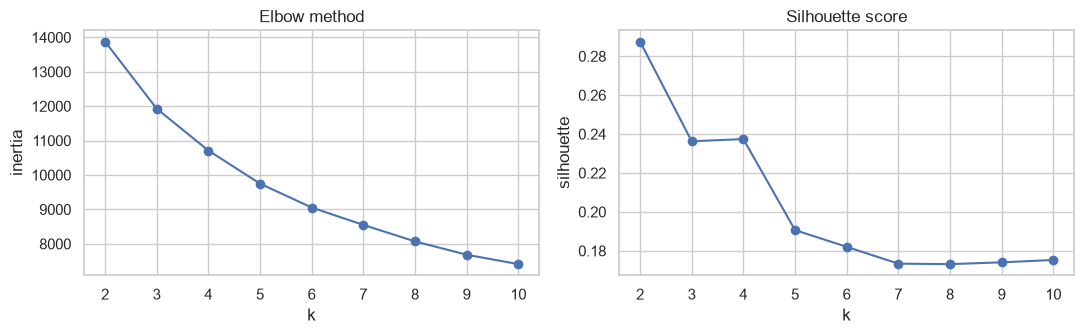

 k  inertia  silhouette
 2  13877.0       0.287
 3  11928.0       0.236
 4  10711.0       0.237
 5   9748.0       0.191
 6   9054.0       0.182
 7   8549.0       0.173
 8   8070.0       0.173
 9   7683.0       0.174
10   7409.0       0.175


In [12]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(ks, inertia, marker="o"); ax[0].set(title="Elbow method", xlabel="k", ylabel="inertia")
ax[1].plot(ks, sil, marker="o"); ax[1].set(title="Silhouette score", xlabel="k", ylabel="silhouette")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"k": ks, "inertia": np.round(inertia), "silhouette": np.round(sil, 3)}).to_string(index=False))

**Figure 4.** Inertia falls fast up to k = 3–4 and slower after that – the "elbow" is around 3. The silhouette is highest for k = 2 (0.287), then k = 3 and k = 4 are almost equal (0.236 / 0.237), and it falls for bigger k. Two segments ("rich" and "poor") are too simple for marketing, so I choose **k = 3**: a good silhouette, the elbow point, and three groups are easy to work with.

In [13]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_scaled)
df["cluster"] = kmeans.labels_
order = df.groupby("cluster")["Total_Spent"].mean().sort_values().index
names = {order[0]: "Budget families", order[1]: "Deal-seeking families", order[2]: "Premium customers"}
df["segment"] = df["cluster"].map(names)
print(df["segment"].value_counts())

segment
Budget families          1001
Premium customers         641
Deal-seeking families     566
Name: count, dtype: int64


**PCA (Principal Component Analysis)** (Jolliffe & Cadima, 2016; Géron, 2019, ch. 8) turns the 9 scaled features into new features – *principal components* – that are combinations of the old ones. The first component is the direction in which customers differ most, the second is the next direction (independent from the first), and so on. **Explained variance** shows what share of all the information each component keeps. We use PCA here for two reasons: to draw 9-dimensional data in 2 dimensions and to see which original features drive the differences between customers.

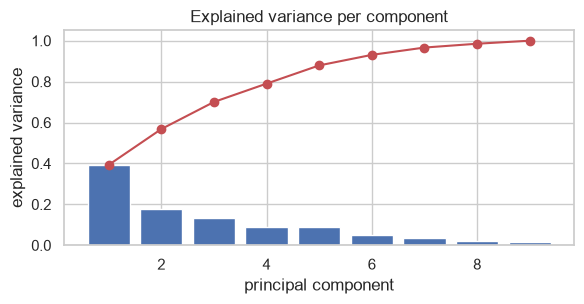

explained variance: [0.393 0.175 0.133 0.09  0.089 0.052 0.036 0.019 0.015] 
cumulative: [0.393 0.568 0.7   0.79  0.879 0.931 0.966 0.985 1.   ]


,PC1,PC2
Age,0.09,0.19
Income,0.47,0.07
Children,-0.33,0.28
Total_Spent,0.49,0.17
Total_Purchases,0.44,0.29
NumWebVisitsMonth,-0.38,0.32
NumDealsPurchases,-0.13,0.63
Tenure_days,0.01,0.51
Accepted_Cmps,0.26,0.09


In [14]:
pca = PCA().fit(X_scaled)
ev = pca.explained_variance_ratio_
plt.figure(figsize=(6, 3.2))
plt.bar(range(1, 10), ev, color="#4C72B0"); plt.plot(range(1, 10), np.cumsum(ev), marker="o", color="#C44E52")
plt.xlabel("principal component"); plt.ylabel("explained variance"); plt.title("Explained variance per component"); plt.tight_layout(); plt.show()
print("explained variance:", ev.round(3), "\ncumulative:", np.cumsum(ev).round(3))
loadings = pd.DataFrame(pca.components_[:2].T, index=features, columns=["PC1", "PC2"]).round(2)
loadings

**Figure 5 and loadings.** PC1 keeps 39 % of the variance, PC2 18 % – together 57 %; 5 components are needed for 88 %. The loadings show what the components mean: **PC1** is "customer value" – high income, high spending, many purchases, few children, few web visits (positive side = rich active buyers, negative side = families with small budgets). **PC2** is "deal hunting and loyalty" – many discount purchases, long tenure, many web visits. So the two main things that separate customers are how much they spend and whether they hunt for discounts.

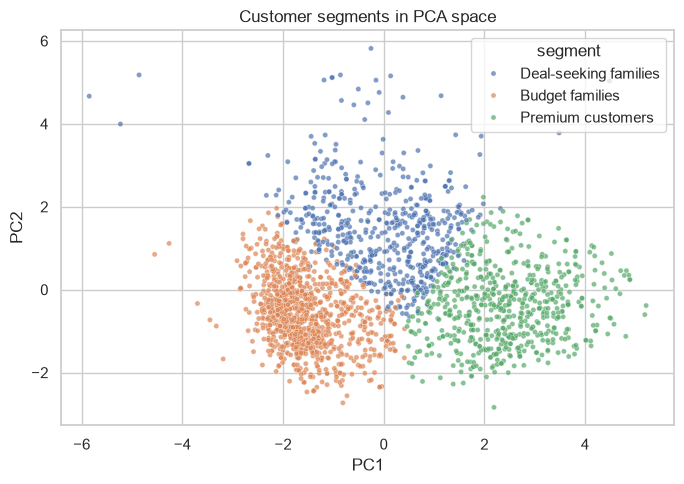

In [15]:
X_pca = PCA(n_components=2).fit_transform(X_scaled)
df["PC1"], df["PC2"] = X_pca[:, 0], X_pca[:, 1]
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="PC1", y="PC2", hue="segment", s=14, alpha=0.7, palette=["#4C72B0", "#DD8452", "#55A868"])
plt.title("Customer segments in PCA space"); plt.tight_layout(); plt.show()

**Figure 6.** In the PCA plot the three segments are well separated along PC1 (customer value): budget families on the left, premium customers on the right, deal-seeking families in the middle and higher on PC2 (more discounts, longer tenure). The borders touch – real customers do not fall into perfect boxes – but the centres of the groups are clearly different.

## 8. Evaluation and Interpretation

In [16]:
print("silhouette (9 scaled features): %.3f" % silhouette_score(X_scaled, df["cluster"]))
print("silhouette (2 PCA components):  %.3f" % silhouette_score(X_pca, df["cluster"]))
profile = df.groupby("segment")[features + ["MntWines", "MntMeatProducts", "MntGoldProds", "Response"]].mean().round(1).loc[list(names.values())]
profile["customers"] = df["segment"].value_counts()
profile["share_of_revenue"] = (df.groupby("segment")["Total_Spent"].sum() / df["Total_Spent"].sum()).round(2)
profile.T

silhouette (9 scaled features): 0.236
silhouette (2 PCA components):  0.450


segment,Budget families,Deal-seeking families,Premium customers
Age,42.30,48.60,46.40
Income,34422.70,55998.70,75723.70
Children,1.20,1.30,0.30
Total_Spent,99.10,723.00,1297.40
Total_Purchases,5.90,16.80,19.10
NumWebVisitsMonth,6.40,6.30,2.90
NumDealsPurchases,1.90,4.50,1.20
Tenure_days,496.40,636.70,517.40
Accepted_Cmps,0.20,0.30,1.00
MntWines,41.50,429.50,607.30


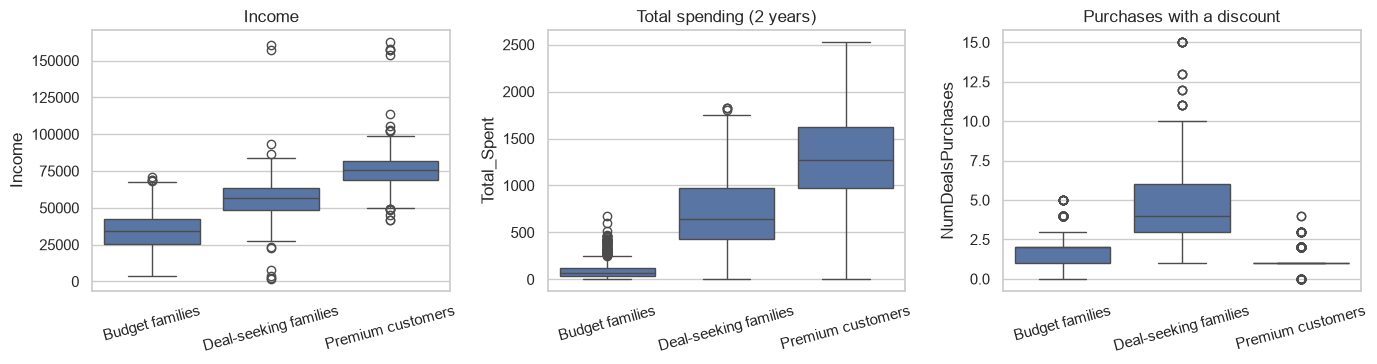

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
seg_order = list(names.values())
sns.boxplot(data=df, x="segment", y="Income", order=seg_order, color="#4C72B0", ax=ax[0]).set(title="Income", xlabel="")
sns.boxplot(data=df, x="segment", y="Total_Spent", order=seg_order, color="#4C72B0", ax=ax[1]).set(title="Total spending (2 years)", xlabel="")
sns.boxplot(data=df, x="segment", y="NumDealsPurchases", order=seg_order, color="#4C72B0", ax=ax[2]).set(title="Purchases with a discount", xlabel="")
for a in ax: a.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

In [18]:
pd.crosstab(df["segment"], df["Education"], normalize="index").round(2).loc[seg_order]

Education,2n Cycle,Basic,Graduation,Master,PhD
segment,,,,,
Budget families,0.11,0.05,0.49,0.17,0.19
Deal-seeking families,0.07,0.00,0.50,0.18,0.25
Premium customers,0.08,0.00,0.54,0.15,0.23


**Quality.** The silhouette score (Rousseeuw, 1987) is 0.236 on the 9 scaled features and 0.450 on the 2 PCA components. For customer data this is a normal, acceptable result: customers form a continuum, not isolated islands, so scores above 0.5 are rare. The PCA plot and the profile table confirm that the three groups are really different.

**Segment profiles** (mean values; the first number is the size of the group):

* **Budget families – 1 001 customers (45 %), 7 % of revenue.** Income ≈ 34 000, spending ≈ 100 for two years, about 6 purchases, 1.2 children, 6.4 web visits per month but few purchases, almost never accept campaigns (0.2). They look at the website and at discounts but have little money.
* **Deal-seeking families – 566 customers (26 %), 31 % of revenue.** Income ≈ 56 000, spending ≈ 720, 17 purchases, 1.3 children, the longest tenure (≈ 640 days) and by far the most purchases with a discount (4.5 vs 1.2–1.9). Loyal middle-class families who buy a lot but wait for deals.
* **Premium customers – 641 customers (29 %), 62 % of revenue.** Income ≈ 76 000, spending ≈ 1 300 (wine ≈ 610, meat ≈ 410), 19 purchases, almost no children (0.3), few web visits (2.9), the highest campaign response (1.0 accepted campaigns, 30 % answered the last one). They buy at full price and react to marketing.

**What makes the segments different:** income and family size first (PC1), then discount behaviour and loyalty (PC2). Education is almost the same in all three groups (about half have a bachelor's degree), so it is not what separates customers.

## 9. Conclusion

* **Data and preparation.** 2 240 customers of a food retailer (Kaggle). Removed 24 rows without income, 4 impossible ages / incomes, 4 joke marital statuses and 2 constant columns → 2 208 customers. Built 9 features (age, income, children, total spending, total purchases, web visits, discount purchases, tenure, accepted campaigns) and scaled them.
* **Method.** K-Means with k chosen by the elbow method and silhouette score; PCA for visualisation and interpretation. k = 3 gives silhouette 0.236 (0.450 in PCA space); PC1 = customer value, PC2 = deal hunting and loyalty.
* **Most meaningful segments.** *Premium customers* – 29 % of customers but 62 % of revenue, respond to campaigns → the main target for premium wine and meat offers and for retention. *Deal-seeking families* – 31 % of revenue, loyal, buy with discounts → targeted coupons and a loyalty programme, no need to send premium offers. *Budget families* – 45 % of customers but 7 % of revenue → low-cost digital communication only, do not spend the marketing budget on catalogs.
* **Business use.** Different campaign content and budget per segment, discounts only where they change behaviour, catalog and premium channel for the premium group, website improvements for the budget group that visits often but buys little.
* **Limitations and improvements.** (1) K-Means makes round clusters of similar size; a Gaussian Mixture Model or DBSCAN could find better-shaped groups. (2) The silhouette score is moderate – adding behaviour over time (monthly purchases) would separate customers better. (3) The data is from 2012–2014 and one company; segments should be re-built on fresh data every year and tested with an A/B campaign to measure the real effect.

## 10. References

Géron, A. (2019). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow: Concepts, tools, and techniques to build intelligent systems* (2nd ed.). O'Reilly Media. (Chapters 8–9: dimensionality reduction and unsupervised learning techniques)

Patel, A. (2021). *Customer personality analysis* [Data set]. Kaggle. https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7

Jolliffe, I. T., & Cadima, J. (2016). Principal component analysis: A review and recent developments. *Philosophical Transactions of the Royal Society A, 374*(2065), 20150202. https://doi.org/10.1098/rsta.2015.0202